# M12 - Object detection, boxes, and mAP

**Level 3 · CPU-only · about 2 hours · no download required**

Detection outputs boxes, classes, and scores. A model that finds an object is not
finished: the output must be decoded, duplicate boxes must be suppressed, and the
result must be scored against ground truth at a stated IoU and confidence
threshold. This notebook trains the section's tiny heatmap detector and reports
those measurements.

## Learning objectives

By the end of this notebook you can:

1. inspect an annotated image and its boxes;
2. compute IoU between two boxes by hand;
3. explain the heatmap, size head, peak decode, and NMS steps;
4. train a small detector on a CPU;
5. evaluate with mAP and per-class precision/recall;
6. explain why a threshold is a product decision, not a universal constant.

## Prerequisites

- M11, or a working understanding of tensors and classification metrics.
- `torch`, `numpy`, `pandas`, `pillow`.
- CPU only. The dataset is synthetic and CC0-1.0; no pretrained weights are used.

## Conceptual explanation

A detector predicts a spatial map of object centres and a box size at each
location. The map is lower resolution than the image, so one cell covers several
pixels. A high score at a cell means "an object centre is near here". Turning that
map into detections requires four steps: sigmoid, local-maximum peak finding,
thresholding, and non-maximum suppression.

The metric is not "did a box appear". A prediction matches a ground-truth box only
when the classes agree and IoU is at least the chosen threshold. mAP integrates
precision and recall across confidence thresholds; this notebook reports mAP at
0.5 and per-class AP so a single number cannot hide a missing class.

## Important terminology

| Term | Meaning |
| --- | --- |
| Box | `(x1, y1, x2, y2)` in pixels, with the far edges exclusive |
| IoU | Intersection area divided by union area |
| Heatmap | Per-class grid of object-centre scores |
| Stride | Pixels per heatmap cell |
| NMS | Non-maximum suppression; removes duplicate overlapping boxes |
| Precision | True positives divided by all predicted positives |
| Recall | True positives divided by all ground-truth objects |
| AP / mAP | Area under the precision-recall curve / mean over classes |


## 1. Set up imports


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
PROJECT = ROOT / "projects" / "computer-vision"
sys.path.insert(0, str(PROJECT))
print("Repository root:", ROOT.name)
print("Section package:", PROJECT.name)


Repository root: AITopics
Section package: computer-vision


In [2]:
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw
from IPython.display import display

from vision_core import dataio, detection, detection_train, metrics

CLASSES = ["circle", "square", "triangle"]
torch.manual_seed(2)
np.random.seed(2)
torch.set_num_threads(2)
print("torch:", torch.__version__)


torch: 2.7.1+cpu


## 2. Load annotated images and inspect the ground truth

Each record has an image and a `meta["boxes"]` list. The box count and class
balance are data facts, not model results. Check them before training.


In [3]:
records = dataio.detection_records(n_images=40, seed=2)[:40]
train_records = records[:30]
test_records = records[30:]

print("records:", len(records))
print("train/test:", len(train_records), len(test_records))
print("boxes:", sum(len(record.meta["boxes"]) for record in records))
print(
    "class counts:",
    pd.Series(
        [box["class"] for record in records for box in record.meta["boxes"]]
    ).value_counts().to_dict(),
)
print("image shape:", records[0].image.shape)


records: 40
train/test: 30 10
boxes: 59
class counts: {'square': 21, 'circle': 21, 'triangle': 17}
image shape: (64, 64, 3)


objects: ['square', 'square']


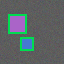

In [4]:
def draw_boxes(record, boxes, colour=(0, 220, 80)):
    image = Image.fromarray(np.asarray(record.image, dtype=np.uint8)).convert("RGB")
    draw = ImageDraw.Draw(image)
    for box in boxes:
        x1, y1, x2, y2 = box["xyxy"] if isinstance(box, dict) else box
        draw.rectangle([x1, y1, x2, y2], outline=colour, width=2)
    return image

sample = records[0]
print("objects:", [box["class"] for box in sample.meta["boxes"]])
display(draw_boxes(sample, sample.meta["boxes"]))


## 3. Compute IoU by hand

IoU is the single most important detection primitive. If two boxes do not
overlap, the intersection is zero. If one box contains the other, the union is
the larger box. This is worth implementing once without a library.


In [5]:
def iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b
    inter_x1 = max(ax1, bx1)
    inter_y1 = max(ay1, by1)
    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)
    inter = max(0.0, inter_x2 - inter_x1) * max(0.0, inter_y2 - inter_y1)
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union else 0.0

print("identical:", round(iou((0, 0, 10, 10), (0, 0, 10, 10)), 3))
print("disjoint:", round(iou((0, 0, 10, 10), (20, 20, 30, 30)), 3))
print("half-overlap:", round(iou((0, 0, 10, 10), (5, 0, 15, 10)), 3))


identical: 1.0
disjoint: 0.0
half-overlap: 0.333


## 4. Train the heatmap detector

The detector has a convolutional trunk and two heads: a class heatmap and a box
size map. Training uses a focal-style heatmap loss and a size loss that is masked
to object centres. The model is tiny; 120 epochs on 30 images finish in seconds.
The point is the decode-and-score pipeline, not a state-of-the-art detector.


In [6]:
import time

started = time.perf_counter()
model, history = detection_train.train_detector(
    train_records,
    num_classes=3,
    epochs=120,
    batch_size=8,
    lr=2e-3,
    seed=2,
    log=False,
)
print("training seconds:", round(time.perf_counter() - started, 2))
print("first/last heat loss:", round(float(history["heat_loss"][0]), 4), round(float(history["heat_loss"][-1]), 4))
print("first/last size loss:", round(float(history["size_loss"][0]), 4), round(float(history["size_loss"][-1]), 4))


training seconds: 2.98
first/last heat loss: 0.2154 0.1242
first/last size loss: 1.1514 0.0453


## 5. Decode predictions and evaluate

The score threshold removes low-confidence cells before matching. `mAP` is
reported at IoU 0.5. A low mAP is not a reason to hide the run; it is the result
you must explain. This tiny detector sees only 30 training images and uses a
coarse 16x16 heatmap.


In [7]:
results = detection.predict_records(
    model,
    test_records,
    score_threshold=0.1,
    nms_iou=0.45,
)
mAP = metrics.mean_average_precision(results, CLASSES)
evaluation = metrics.evaluate_detections(results, CLASSES, score_threshold=0.1)

print("predicted boxes:", sum(len(result.predictions) for result in results))
print("mAP@0.5:", round(mAP["map"], 3))
print("per-class AP@0.5:", {key: round(value, 3) for key, value in mAP["per_class_ap50"].items()})
print(
    "precision/recall/F1:",
    {key: round(evaluation[key], 3) for key in ("precision", "recall", "f1")},
)


predicted boxes: 82
mAP@0.5: 0.169
per-class AP@0.5: {'circle': 0.381, 'square': 0.042, 'triangle': 0.083}
precision/recall/F1: {'precision': 0.073, 'recall': 0.429, 'f1': 0.125}


In [8]:
rows = []
for class_name, values in evaluation["per_class"].items():
    tp, fp, fn = values["tp"], values["fp"], values["fn"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    rows.append(
        {
            "class": class_name,
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "precision": round(precision, 3),
            "recall": round(recall, 3),
        }
    )
pd.DataFrame(rows)


,class,tp,fp,fn,precision,recall
0,circle,4,26,2,0.133,0.667
1,square,1,27,3,0.036,0.250
2,triangle,1,23,3,0.042,0.250


## 6. Inspect one prediction image

A metric table is not a debugging tool. Draw the predictions, compare them with
the ground truth, and look for the specific failure: missed small objects,
duplicate boxes, class confusion, or boxes that are the right class but the wrong
size.


ground truth: ['square']
predictions: [{'xyxy': [32.7, 32.5, 51.3, 51.5], 'class': 'circle', 'score': 0.958}, {'xyxy': [23.8, 28.2, 36.2, 39.8], 'class': 'square', 'score': 0.93}, {'xyxy': [22.4, 34.8, 37.6, 49.2], 'class': 'square', 'score': 0.887}, {'xyxy': [12.3, 32.3, 31.7, 51.7], 'class': 'square', 'score': 0.831}, {'xyxy': [39.1, 19.3, 60.9, 40.7], 'class': 'triangle', 'score': 0.208}, {'xyxy': [34.8, 47.6, 49.2, 60.4], 'class': 'triangle', 'score': 0.117}]


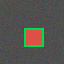

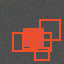

In [9]:
first = test_records[0]
first_result = results[0]
predicted_boxes = [
    {"xyxy": [round(value, 1) for value in annotation.box], "class": CLASSES[annotation.class_id], "score": round(annotation.score, 3)}
    for annotation in first_result.predictions
]
print("ground truth:", [box["class"] for box in first.meta["boxes"]])
print("predictions:", predicted_boxes)
display(draw_boxes(first, first.meta["boxes"], colour=(0, 220, 80)))
display(draw_boxes(first, [item["xyxy"] for item in predicted_boxes], colour=(240, 80, 40)))


## Explanation of the code

- `train_detector` builds Gaussian heatmap targets from boxes; a box is not fed to
  the network as a list of four numbers.
- The heatmap has one channel per class. A local maximum is a candidate object
  centre; the size head provides width and height at that centre.
- `predict_records` calls `decode_heatmap`, which applies sigmoid, peak finding,
  thresholding, box construction, and NMS in that order.
- `mean_average_precision` sorts predictions by score across the dataset and
  integrates the precision-recall curve per class.
- The displayed images are two separate renders: green boxes are truth, orange
  boxes are predictions. The model does not see the green boxes at inference.

## Expected output

You should see 40 images, a class-count table, three IoU sanity checks, a short
training summary, a finite mAP, per-class precision/recall, and two images with
boxes. The seeded run stored here reports mAP@0.5 = 0.169, precision 0.073, and
recall 0.429. That is a modest result: 30 training images and a coarse
heatmap are enough to demonstrate the pipeline, not to build a production
detector.

## Interpretation of results

On this run mAP@0.5 is **0.169**: averaged across the three classes, the
precision-recall curve at IoU 0.5 is weak. Per-class AP makes the failure
concrete: circle 0.381, square 0.042, triangle 0.083. At the chosen threshold the
detector emits 82 boxes for 59 ground-truth objects, so recall is 0.429 but
precision is only 0.073. In practical terms, the pipeline finds some objects and
ranks the circle class best, but most high-confidence boxes are false positives
or poorly localised. This is a working teaching baseline, not a production
detector. Never report mAP without the IoU threshold, the confidence threshold,
the test split, and the number of ground-truth objects, and do not compare this
number with benchmark results on real datasets.

## Practical exercises

1. Change the score threshold from 0.1 to 0.5 and compare precision and recall.
2. Compute IoU for two ground-truth boxes that overlap; explain why matching uses
   one-to-one assignment.
3. Train for 20 epochs instead of 120 and compare mAP. Is the difference worth
   the compute?
4. Draw a duplicate prediction and explain which NMS parameter would remove it.

## Challenge

Evaluate the detector on a held-out condition or class. Report mAP@0.5 and one
concrete failure mode from an image. Propose a single change that would address
that failure, and state what could regress if you make it.

## Limitations

The detector is trained on 30 synthetic 64x64 images with a coarse 16x16 heatmap
and no pretrained backbone. That budget is adequate to debug heatmap targets,
decoding, NMS, and matching, but not to produce a deployable detector. The test
split is tiny, so one box changes mAP noticeably, and the score threshold was
chosen for diagnosis rather than tuned on a validation set. Use the image
inspection and per-class table to explain failures; do not present the headline
mAP as production performance.

## Common mistakes and troubleshooting

| Symptom | Likely cause | Fix |
| --- | --- | --- |
| No predictions | Score threshold too high for an undertrained model | Lower it for diagnosis, then report the chosen value |
| mAP is zero | Class ids or box coordinate order are wrong | Check `CLASSES`, box order, and image size |
| Many duplicate boxes | NMS disabled or threshold too high | Inspect NMS IoU and raw peaks |
| Boxes are tiny | Size head not trained or target mask wrong | Check size loss and target construction |
| Test image looks correct but metric is low | Coordinate convention differs between truth and prediction | Print both boxes for one object |
| GPU code fails | The section's CPU path does not require CUDA | Keep `device="cpu"`; report GPU work separately |

## Summary

You trained and evaluated a detector, computed IoU, decoded heatmaps into boxes,
applied NMS, and inspected a real failure. The evidence is a metric table plus an
image, not a claim that "the detector works".

## Further reading

- Ren et al., "Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks", NeurIPS 2015.
- Redmon et al., "You Only Look Once: Unified, Real-Time Object Detection", CVPR 2016.
- Lin et al., "Focal Loss for Dense Object Detection", ICCV 2017.
- COCO detection evaluation documentation, including IoU and mAP definitions.
- The repository's `vision_core.detection`, `vision_core.detection_train`, and `vision_core.metrics`.
